# Named Entity Recognition (NER) — Tutorial

**CS 6120 — Natural Language Processing**

**Before you start:** set the runtime to GPU via *Runtime → Change runtime type → GPU*.


## Setup
Run this once. It installs the libraries and downloads the small spaCy + NLTK models.


In [ ]:
!pip install -q spacy nltk transformers datasets svgling accelerate
!python -m spacy download en_core_web_sm -q

import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('maxent_ne_chunker')
nltk.download('maxent_ne_chunker_tab')
nltk.download('words')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.1/67.1 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 33.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping chunkers/maxent_ne_chunker.zip.
[nltk_data] Downloading package maxent_ne_chunker_tab to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping chunkers/maxent_ne_chunker_tab.zip.
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Unzipping corpora/words.zip.


True

## Named Entity Recognition (NER)

Named-entity recognition locates and classifies named entities in unstructured text into predefined categories such as person names, organizations, locations, medical codes, and time expressions.

It helps answer questions like: which companies and people are mentioned in a document, in which posts a given product appears, or whether an article contains medical terms.

NER is usually split into two subproblems: **detecting** the name spans (a single name may span several tokens, e.g. *Bank of America*) and **classifying** each detected name by entity type.


## Applications

- Categorizing and filtering customer support requests to surface insights about customers.
- Speeding up screening by categorizing applicants' CVs.
- Improving search and recommendation engines using recognized entities.
- Extracting useful information from documents and posts.


## POS Tagging

**Part-of-Speech (POS) tagging** marks up each word in a text with its grammatical category (noun, verb, adjective, etc.) based on definition and context. It is a common first step before chunking into named entities.


In [ ]:
import numpy as np
import pandas as pd
from nltk import word_tokenize, pos_tag

ex = "Experts in France said the French economy is recovering, according to Reuters and the World Bank."

# tokenize the sentence and apply POS tagging
sent = pos_tag(word_tokenize(ex))
sent

[('Experts', 'NNS'),
 ('in', 'IN'),
 ('France', 'NNP'),
 ('said', 'VBD'),
 ('the', 'DT'),
 ('French', 'JJ'),
 ('economy', 'NN'),
 ('is', 'VBZ'),
 ('recovering', 'VBG'),
 (',', ','),
 ('according', 'VBG'),
 ('to', 'TO'),
 ('Reuters', 'NNPS'),
 ('and', 'CC'),
 ('the', 'DT'),
 ('World', 'NNP'),
 ('Bank', 'NNP'),
 ('.', '.')]

Each tuple is `(word, POS-tag)`. For example `NNP` is a proper noun (*France*), `NNS` a plural noun, and `JJ` an adjective (*French*). A full tag reference is [here](https://www.guru99.com/pos-tagging-chunking-nltk.html).

## Chunking

**Chunking** groups small pieces (individual tagged words) into larger units, most commonly *noun phrases*. It adds structure on top of POS tagging using regex-style patterns over tags. To chunk one or more adjacent nouns we use the pattern `<NN.*>+`.


After Chunking (S
  (mychunk Experts/NNS)
  in/IN
  (mychunk France/NNP)
  said/VBD
  the/DT
  French/JJ
  (mychunk economy/NN)
  is/VBZ
  recovering/VBG
  ,/,
  according/VBG
  to/TO
  (mychunk Reuters/NNPS)
  and/CC
  the/DT
  (mychunk World/NNP Bank/NNP)
  ./.)


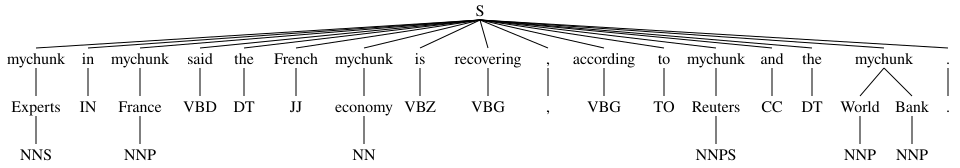

In [ ]:
from nltk import RegexpParser
import svgling

# chunk runs of adjacent nouns
patterns = """mychunk:{<NN.*>+}"""
chunker = RegexpParser(patterns)
output = chunker.parse(sent)
print("After Chunking", output)
svgling.draw_tree(output)

## IOB Tags

Like POS tags, **IOB tags** represent chunk structure by marking the **I**nside, **O**utside, and **B**eginning of each chunk. This is the standard tagging scheme for sequence-labeling tasks like NER.


In [ ]:
from nltk.chunk import tree2conlltags

iob_tagged = tree2conlltags(output)
iob_tagged

[('Experts', 'NNS', 'B-mychunk'),
 ('in', 'IN', 'O'),
 ('France', 'NNP', 'B-mychunk'),
 ('said', 'VBD', 'O'),
 ('the', 'DT', 'O'),
 ('French', 'JJ', 'O'),
 ('economy', 'NN', 'B-mychunk'),
 ('is', 'VBZ', 'O'),
 ('recovering', 'VBG', 'O'),
 (',', ',', 'O'),
 ('according', 'VBG', 'O'),
 ('to', 'TO', 'O'),
 ('Reuters', 'NNPS', 'B-mychunk'),
 ('and', 'CC', 'O'),
 ('the', 'DT', 'O'),
 ('World', 'NNP', 'B-mychunk'),
 ('Bank', 'NNP', 'I-mychunk'),
 ('.', '.', 'O')]

## Extracting Named Entities (NLTK)

Recognizing a named entity is a specialized chunk extraction using entity tags such as **PERSON, LOCATION, ORGANIZATION**. NLTK ships a pretrained chunker accessible via `ne_chunk()`.


In [ ]:
from nltk.chunk import ne_chunk

def extract_ne(trees, labels):
    ne_list = []
    # iterate over the passed-in trees
    for tree in trees:
        if hasattr(tree, 'label') and tree.label() in labels:
            ne_list.append(tree)
    return ne_list

ne_res = ne_chunk(pos_tag(word_tokenize(ex)))
labels = ['ORGANIZATION']

print(extract_ne(ne_res, labels))

[Tree('ORGANIZATION', [('Reuters', 'NNPS')]), Tree('ORGANIZATION', [('World', 'NNP'), ('Bank', 'NNP')])]


## spaCy Named Entity Recognition

spaCy provides a fast statistical entity recognizer that labels contiguous spans of tokens. Its default English pipeline recognizes companies, locations, organizations, products, dates, and more.


In [ ]:
wiki_ex = (
    "Alan Turing was a British mathematician born in London in 1912. "
    "He worked at the University of Cambridge and later joined the "
    "Government Code and Cypher School at Bletchley Park during World War II, "
    "where he helped design machines to break the German Enigma cipher. "
    "In 1950 he published a paper in the journal Mind, and Google now hosts "
    "an annual award named after him. He died in 1954."
)

In [ ]:
import spacy

nlp = spacy.load("en_core_web_sm")
doc = nlp(wiki_ex)
doc

Alan Turing was a British mathematician born in London in 1912. He worked at the University of Cambridge and later joined the Government Code and Cypher School at Bletchley Park during World War II, where he helped design machines to break the German Enigma cipher. In 1950 he published a paper in the journal Mind, and Google now hosts an annual award named after him. He died in 1954.

In [ ]:
print('All entity types spaCy recognized in the document above')
set([ent.label_ for ent in doc.ents])

All entity types spaCy recognized in the document above


{'DATE', 'EVENT', 'FAC', 'GPE', 'LAW', 'NORP', 'ORG', 'PERSON', 'PRODUCT'}

In [ ]:
print('Persons:')
print(set([ent for ent in doc.ents if ent.label_ == 'PERSON']))
print('Organizations:')
print(set([ent for ent in doc.ents if ent.label_ == 'ORG']))

Persons:
{Alan Turing}
Organizations:
{the University of Cambridge, Cypher School, Google}


## Visualizing Named Entities (spaCy)


In [ ]:
from spacy import displacy
displacy.render(doc, style="ent", jupyter=True)

## NER with BERT (Hugging Face)

**BERT** (Bidirectional Encoder Representations from Transformers) reads context in both directions, giving strong word-in-context representations. Beyond classification, summarization, and QA, it handles NER well.

The Hugging Face `pipeline` gives one-line access to pretrained token-classification models. Browse them under the *Token Classification* tag on the Hub.


In [ ]:
from transformers import pipeline

# same embedded example sentence as before
ex = "Experts in France said the French economy is recovering, according to Reuters and the World Bank."

generator = pipeline("ner", aggregation_strategy="simple")  # groups sub-word tokens into whole entities
generator(ex)

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'LOC',
  'score': np.float32(0.99986506),
  'word': 'France',
  'start': 11,
  'end': 17},
 {'entity_group': 'MISC',
  'score': np.float32(0.99922264),
  'word': 'French',
  'start': 27,
  'end': 33},
 {'entity_group': 'ORG',
  'score': np.float32(0.99818385),
  'word': 'Reuters',
  'start': 70,
  'end': 77},
 {'entity_group': 'ORG',
  'score': np.float32(0.9991293),
  'word': 'World Bank',
  'start': 86,
  'end': 96}]

## Fine-tuning an Existing BERT Model

Training from scratch is expensive, so we take a model that already understands English (`dslim/bert-base-NER`) and continue training it a little on our own annotated data. This is **transfer learning / fine-tuning**.

The annotated corpus below is the GMB-derived *Entity Annotated Corpus*, pulled automatically from the Hugging Face mirror (~28 MB) so there is nothing to upload.


In [ ]:
from datasets import load_dataset
import pandas as pd

# Auto-download the 'Entity Annotated Corpus' from its HF mirror (~3.4 MB).
hf = load_dataset("rjac/kaggle-entity-annotated-corpus-ner-dataset", split="train")

id2tag = {
    0: 'O',
    1: 'B-per', 2: 'I-per',
    3: 'B-geo', 4: 'I-geo',
    5: 'B-org', 6: 'I-org',
    7: 'B-gpe', 8: 'I-gpe',
    9: 'B-tim', 10: 'I-tim',
    11: 'B-art', 12: 'I-art',
    13: 'B-eve', 14: 'I-eve',
    15: 'B-nat', 16: 'I-nat',
}

def ids_to_tags(ids):
    return [id2tag[i] for i in ids]

df_gr = pd.DataFrame({
    "Word": [list(t) for t in hf["tokens"]],
    "Tag":  [ids_to_tags(t) for t in hf["ner_tags"]],
})

# sanity check: every id we saw must be in our mapping
seen = sorted(set(i for row in hf["ner_tags"] for i in row))
missing = [i for i in seen if i not in id2tag]
print("Distinct ids present:", seen)
print("Unmapped ids (should be empty):", missing)
df_gr.head()

README.md:   0%|          | 0.00/2.11k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.86k [00:00<?, ?B/s]

data/train-00000-of-00004-e7c482bd9e7404(…):   0%|          | 0.00/857k [00:00<?, ?B/s]

data/train-00001-of-00004-8e5af59a8884c0(…):   0%|          | 0.00/860k [00:00<?, ?B/s]

data/train-00002-of-00004-8838aa9871a9e9(…):   0%|          | 0.00/857k [00:00<?, ?B/s]

data/train-00003-of-00004-d4161cf902a010(…):   0%|          | 0.00/823k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/47959 [00:00<?, ? examples/s]

Distinct ids present: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
Unmapped ids (should be empty): []


,Word,Tag
0,"[Thousands, of, demonstrators, have, marched, ...","[O, O, O, O, O, O, B-org, O, O, O, O, O, B-org..."
1,"[Iranian, officials, say, they, expect, to, ge...","[B-gpe, O, O, O, O, O, O, O, O, O, O, O, O, O,..."
2,"[Helicopter, gunships, Saturday, pounded, mili...","[O, O, B-tim, O, O, O, O, O, B-org, O, O, O, O..."
3,"[They, left, after, a, tense, hour-long, stand...","[O, O, O, O, O, O, O, O, O, O, O]"
4,"[U.N., relief, coordinator, Jan, Egeland, said...","[B-org, O, O, B-per, I-per, O, B-tim, O, B-org..."


**Note on labels:** the HF mirror stores tags in uppercase BIO form (e.g. `B-GEO`, `I-PER`). We lowercase the entity suffix so they match the `entity_mapping` used below (`B-geo`, `I-per`, ...). If your copy already uses that casing this step is a no-op.


In [ ]:
tags = []
for tag in df_gr['Tag'].to_list():
    tags.extend(tag)
print('Entities in our data set')
set(tags)

Entities in our data set


{'B-art',
 'B-eve',
 'B-geo',
 'B-gpe',
 'B-nat',
 'B-org',
 'B-per',
 'B-tim',
 'I-art',
 'I-eve',
 'I-geo',
 'I-gpe',
 'I-nat',
 'I-org',
 'I-per',
 'I-tim',
 'O'}

In [ ]:
from transformers import AutoModelForTokenClassification

model_checkpoint = "dslim/bert-base-NER"
model = AutoModelForTokenClassification.from_pretrained(model_checkpoint)

print('Entities from the pretrained model')
model.config.id2label

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/433M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Entities from the pretrained model


{0: 'O',
 1: 'B-MISC',
 2: 'I-MISC',
 3: 'B-PER',
 4: 'I-PER',
 5: 'B-ORG',
 6: 'I-ORG',
 7: 'B-LOC',
 8: 'I-LOC'}

Our dataset has more entity types than the pretrained model outputs. We map each of our tags to one of the model's label ids. Types the model doesn't cover are collapsed to id `1` so training still runs; the three types it does share (per / org / geo) keep their proper ids.


In [ ]:
entity_mapping = {
    'O': 0, 'B-per': 3, 'I-per': 4, 'B-org': 5, 'I-org': 6, 'B-geo': 7, 'I-geo': 8,
    'B-art': 1, 'B-eve': 1, 'B-gpe': 1, 'B-nat': 1, 'B-tim': 1,
    'I-art': 1, 'I-eve': 1, 'I-gpe': 1, 'I-nat': 1, 'I-tim': 1,
}

The dataset class below tokenizes each word into sub-word pieces and repeats that word's label across its pieces (e.g. *running → run, ##ning* both get the same tag), then adds `[CLS]`/`[SEP]`, an attention mask, and padding up to `MAX_LEN`.


In [ ]:
import torch

class NERDataset:
    def __init__(self, df):
        self.texts = df['Word'].to_list()
        self.tags = df['Tag'].to_list()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = self.texts[item]
        tags = self.tags[item]
        ids, target_tag = [], []

        # tokenize each word; repeat its tag across sub-word pieces
        for i, s in enumerate(text):
            inputs = tokenizer.encode(s, add_special_tokens=False)
            input_len = len(inputs)
            ids.extend(inputs)
            target_tag.extend([entity_mapping[tags[i]]] * input_len)

        # truncate to leave room for [CLS] and [SEP]
        ids = ids[:MAX_LEN - 2]
        target_tag = target_tag[:MAX_LEN - 2]

        # special tokens
        ids = [101] + ids + [102]
        target_tag = [0] + target_tag + [0]
        mask = [1] * len(ids)
        token_type_ids = [0] * len(ids)

        # pad
        padding_len = MAX_LEN - len(ids)
        ids = ids + ([0] * padding_len)
        mask = mask + ([0] * padding_len)
        token_type_ids = token_type_ids + ([0] * padding_len)
        target_tag = target_tag + ([0] * padding_len)

        return {
            'input_ids': torch.tensor(ids, dtype=torch.long),
            'attention_mask': torch.tensor(mask, dtype=torch.long),
            'token_type_ids': torch.tensor(token_type_ids, dtype=torch.long),
            'labels': torch.tensor(target_tag, dtype=torch.long),
        }

In [ ]:
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

df_train, df_val = train_test_split(df_gr, test_size=0.2, random_state=42)
df_val, df_test = train_test_split(df_val, test_size=0.5, random_state=42)

tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
MAX_LEN = 128

data_train = NERDataset(df_train)
data_val = NERDataset(df_val)
data_test = NERDataset(df_test)

loader_train = torch.utils.data.DataLoader(data_train, batch_size=32, num_workers=2)
loader_val = torch.utils.data.DataLoader(data_val, batch_size=32, num_workers=2)

tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

**Training.** We freeze BERT and train only the classification head on top (fast, works on a single Colab GPU). To fine-tune the whole model instead, swap in the commented-out optimizer line.


In [ ]:
from transformers import get_scheduler
from torch.optim import AdamW
from tqdm.notebook import tqdm
from sklearn.metrics import f1_score, accuracy_score

model = AutoModelForTokenClassification.from_pretrained(model_checkpoint)

# train just the linear classifier on top of BERT
param_optimizer = list(model.classifier.named_parameters())
optimizer_grouped_parameters = [{'params': [p for n, p in param_optimizer]}]
optimizer = AdamW(optimizer_grouped_parameters, lr=3e-5, eps=1e-12)
## full fine-tuning:
# optimizer = AdamW(model.parameters(), lr=3e-5)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)

num_epochs = 3
num_training_steps = num_epochs * len(loader_train)
lr_scheduler = get_scheduler('linear', optimizer=optimizer,
                             num_warmup_steps=0, num_training_steps=num_training_steps)

progress_bar = tqdm(range(num_training_steps))
for epoch in range(num_epochs):
    model.train()
    final_loss = 0
    predictions, true_labels = [], []
    for batch in loader_train:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()
        true_labels.extend(batch['labels'].detach().cpu().numpy().ravel())
        predictions.extend(np.argmax(outputs[1].detach().cpu().numpy(), axis=2).ravel())
        optimizer.step()
        lr_scheduler.step()
        optimizer.zero_grad()
        progress_bar.update(1)
        final_loss += loss.item()
    print(f'Training loss: {final_loss/len(loader_train)}')
    print('Training F1: {}'.format(f1_score(predictions, true_labels, average="macro")))
    print(f'Training acc: {accuracy_score(predictions, true_labels)}')
    print('*' * 20)

    model.eval()
    final_loss = 0
    predictions, true_labels = [], []
    with torch.no_grad():
        for batch in loader_val:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            final_loss += outputs.loss.item()
            true_labels.extend(batch['labels'].detach().cpu().numpy().ravel())
            predictions.extend(np.argmax(outputs[1].detach().cpu().numpy(), axis=2).ravel())
    print(f'Validation loss: {final_loss/len(loader_val)}')
    print('Validation F1: {}'.format(f1_score(predictions, true_labels, average="macro")))
    print(f'Validation acc: {accuracy_score(predictions, true_labels)}')
    print('*' * 20)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/3597 [00:00<?, ?it/s]

Training loss: 0.240432837842851
Training F1: 0.2717462195933638
Training acc: 0.9425378987802018
********************
Validation loss: 0.13638623009125392
Validation F1: 0.3524897416906143
Validation acc: 0.9671747940992493
********************
Training loss: 0.1176883579853975
Training F1: 0.39947370679936856
Training acc: 0.9721981944118644
********************
Validation loss: 0.10948808021843433
Validation F1: 0.44270574458272705
Validation acc: 0.9745474744578816
********************
Training loss: 0.1058655023649397
Training F1: 0.4359757486953886
Training acc: 0.9745396841686866
********************
Validation loss: 0.10382685462633769
Validation F1: 0.46143239543543607
Validation acc: 0.97573335852794
********************


**Test the fine-tuned model** on a fresh sentence.


In [ ]:
test_sentence = (
    "Mr. Trump’s tweets began just moments after a Fox News report by Mike Tobin, "
    "a reporter for the network, about protests in Minnesota and elsewhere."
)

tokenized_sentence = tokenizer.encode(test_sentence)
# .to(device) instead of hardcoded .cuda() so this also works on CPU runtimes
input_ids = torch.tensor([tokenized_sentence]).to(device)

model.eval()
with torch.no_grad():
    output = model(input_ids)
label_indices = np.argmax(output[0].to('cpu').numpy(), axis=2)

# join word-piece tokens back into whole words
tokens = tokenizer.convert_ids_to_tokens(input_ids.to('cpu').numpy()[0])
new_tokens, new_labels = [], []
for token, label_idx in zip(tokens, label_indices[0]):
    if token.startswith('##'):
        new_tokens[-1] = new_tokens[-1] + token[2:]
    else:
        new_labels.append(label_idx)
        new_tokens.append(token)

for token, label in zip(new_tokens, new_labels):
    print('{}\t{}'.format(model.config.id2label[label], token))

O	[CLS]
O	Mr
O	.
I-PER	Trump
O	’
O	s
O	tweets
O	began
O	just
O	moments
O	after
O	a
B-LOC	Fox
O	News
O	report
O	by
B-PER	Mike
I-PER	Tobin
O	,
O	a
O	reporter
O	for
O	the
O	network
O	,
O	about
O	protests
O	in
B-ORG	Minnesota
O	and
O	elsewhere
O	.
O	[SEP]


## References

- Wikipedia: Named-entity recognition
- NLTK & spaCy NER tutorials (Towards Data Science, GeeksforGeeks)
- spaCy linguistic features: named entities
- Hugging Face course, chapter on token classification
- *depends-on-the-definition.com* — NER with BERT
